# Comparativa de modelos

Curvas de todas las ejecuciones de las iteraciones 1 a 9 (`docs/iteraciones.md`) y de dos
controles, y unas pocas figuras para entender y defender el modelo final (la configuracion
congelada de `it6_3bloques`). Solo lee `results/`, `models/` y las imagenes de validacion:
**test no se carga**.

Los calculos estan en `src/utils/figuras.py` (probados en `tests/test_figuras.py`); aqui
solo se llaman y se muestran. Las figuras del informe se guardan en `docs/figuras/`
con el prefijo `comparativa_`.

In [1]:
import sys
from pathlib import Path

# El cuaderno vive en notebooks/: la raiz del repo (donde esta src/) va al path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(REPO))

# torch ANTES que matplotlib: al reves, en Windows chocan sus DLL y el kernel muere al dibujar
import torch  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.utils import figuras as fg

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)

faltan = fg.faltan()
print("Ejecuciones que faltan en results/:", faltan or "ninguna")
ej = {n: fg.leer_ejecucion(n) for ns in fg.EJECUCIONES.values() for n in ns if n not in faltan}
print(f"{len(ej)} ejecuciones leidas")

Ejecuciones que faltan en results/: ninguna
53 ejecuciones leidas


## A. Inventario

Una fila por ejecucion: configuracion, parametros, fold, epocas, epoca elegida y los AUC de
validacion por paciente (medio de todas las epocas, medio de las 1-15 y el de la epoca
elegida), el AUC de train en la epoca 15 y la perdida de validacion minima junto a la de un
modelo constante con la misma perdida. Mirar sobre todo el AUC medio (el elegido esta inflado
por elegir la epoca con la propia validacion) y si la perdida minima baja de la constante.

In [2]:
inv = fg.inventario()
destino = config.RESULTADOS / "comparacion"
destino.mkdir(parents=True, exist_ok=True)
inv.to_csv(destino / "inventario.csv", index=False)
print(f"Guardado en {(destino / 'inventario.csv').relative_to(config.REPO)} ({len(inv)} filas)")
columnas = ["iteracion", "nombre", "configuracion", "parametros", "fold", "epocas", "epoca_elegida",
            "auc_val_medio", "auc_val_medio_1_15", "auc_elegido", "auc_train_15", "perdida_val_min",
            "perdida_constante"]
display(inv[columnas].round(3))

Guardado en results\comparacion\inventario.csv (53 filas)


,iteracion,nombre,configuracion,parametros,fold,epocas,epoca_elegida,auc_val_medio,auc_val_medio_1_15,auc_elegido,auc_train_15,perdida_val_min,perdida_constante
0,1,it1_normal_f0,16-32-64-128 · 256 px · media · normal · aum,294129,0,15,2,0.542,0.542,0.589,0.727,0.602,0.605
1,1,it1_ponderada_f0,16-32-64-128 · 256 px · media · ponderada · aum,294129,0,15,1,0.509,0.509,0.579,0.719,0.978,0.977
2,2,it2_pequena_reg_f0,8-16-32-64 · 256 px · media · normal · aum · w...,73913,0,15,2,0.564,0.564,0.612,0.694,0.598,0.605
3,2,it2_lr1e-4_f0,16-32-64-128 · 256 px · media · normal · aum ·...,294129,0,15,4,0.516,0.516,0.554,0.735,0.611,0.605
4,3,it3_pequena_realce_f0,8-16-32-64 · 256 px · media · normal · aum · r...,74057,0,15,6,0.522,0.522,0.577,0.722,0.601,0.605
5,3,it3_pequena_norm_f0,8-16-32-64 · 256 px · media · normal · aum · n...,73913,0,26,18,0.530,0.536,0.573,0.720,0.609,0.605
6,4,it4_pequena_reg_f1,8-16-32-64 · 256 px · media · normal · aum · w...,73913,1,15,2,0.531,0.531,0.561,0.734,0.621,0.596
7,4,it4_pequena_reg_f2,8-16-32-64 · 256 px · media · normal · aum · w...,73913,2,20,12,0.557,0.565,0.582,0.596,0.565,0.581
8,4,it4_pequena_reg_f3,8-16-32-64 · 256 px · media · normal · aum · w...,73913,3,30,22,0.515,0.491,0.528,0.706,0.674,0.642
9,4,it4_pequena_reg_f4,8-16-32-64 · 256 px · media · normal · aum · w...,73913,4,15,4,0.553,0.553,0.594,0.701,0.589,0.596


## B. Curvas por ejecucion

Tres paneles por ejecucion, agrupadas por iteracion: perdida de train y validacion (la linea
de puntos es la perdida de un modelo constante), AUC de train, validacion y validacion
suavizada (la discontinua vertical es la epoca elegida; la de puntos, el azar) y el lr. Las
ejecuciones con la misma perdida comparten eje. Mirar si train y validacion suben juntas o
si train sube mientras validacion se queda plana (memoriza), y si la perdida de validacion
llega a bajar de la constante.

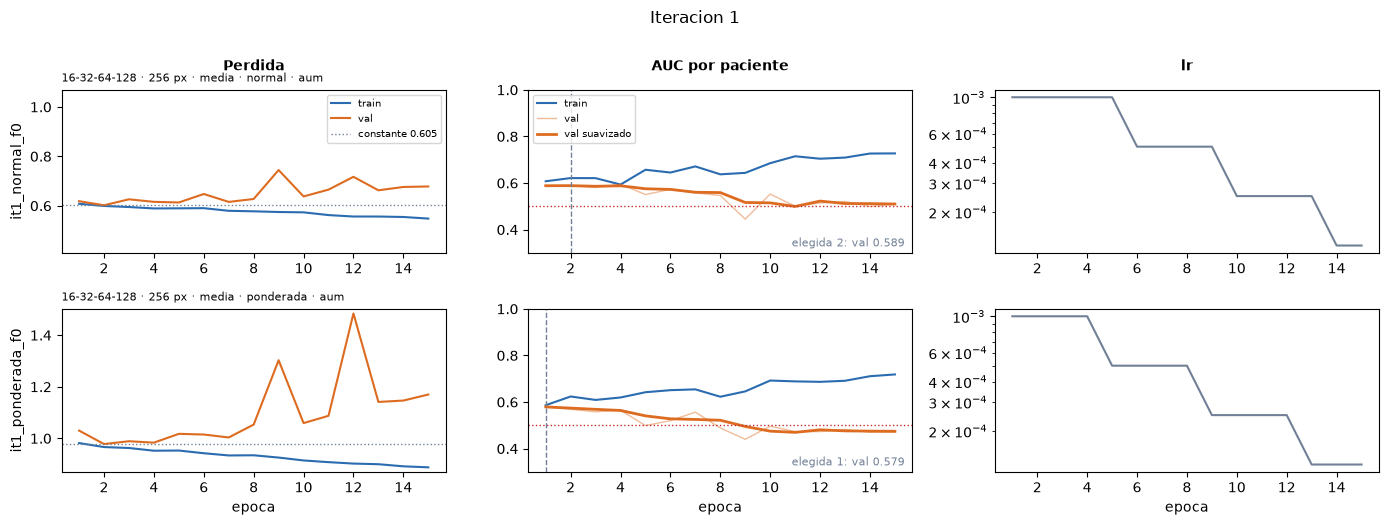

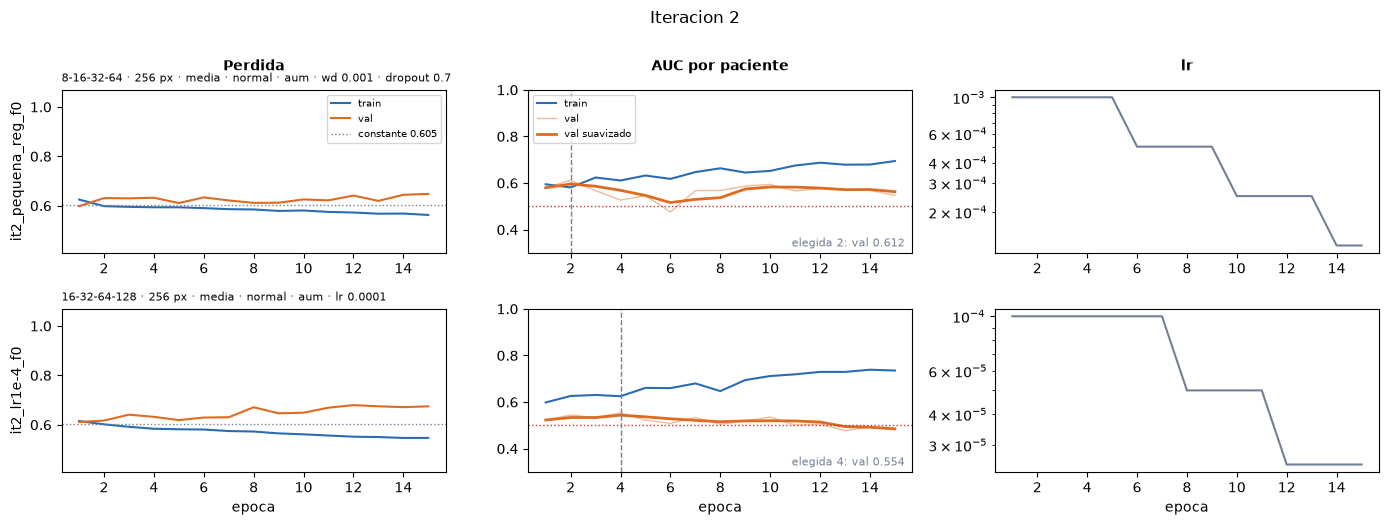

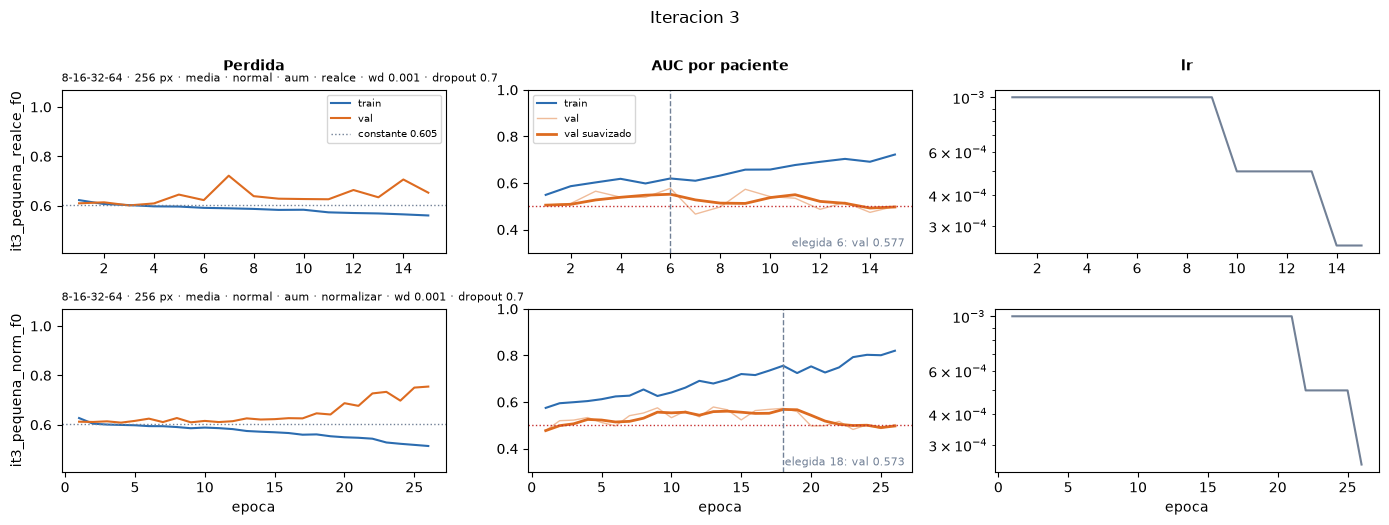

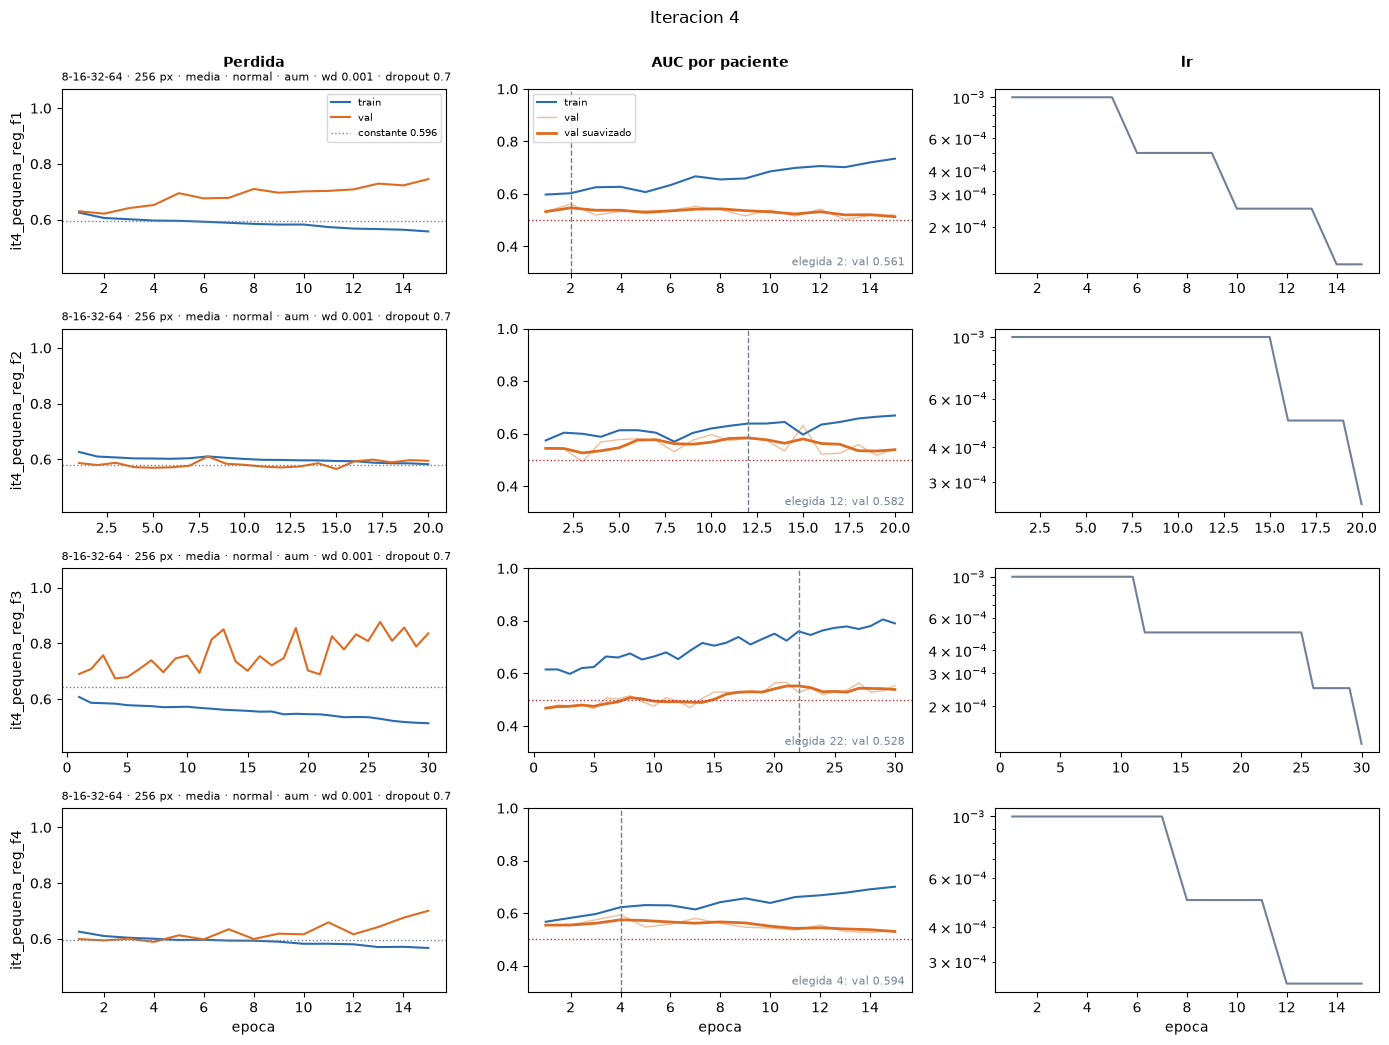

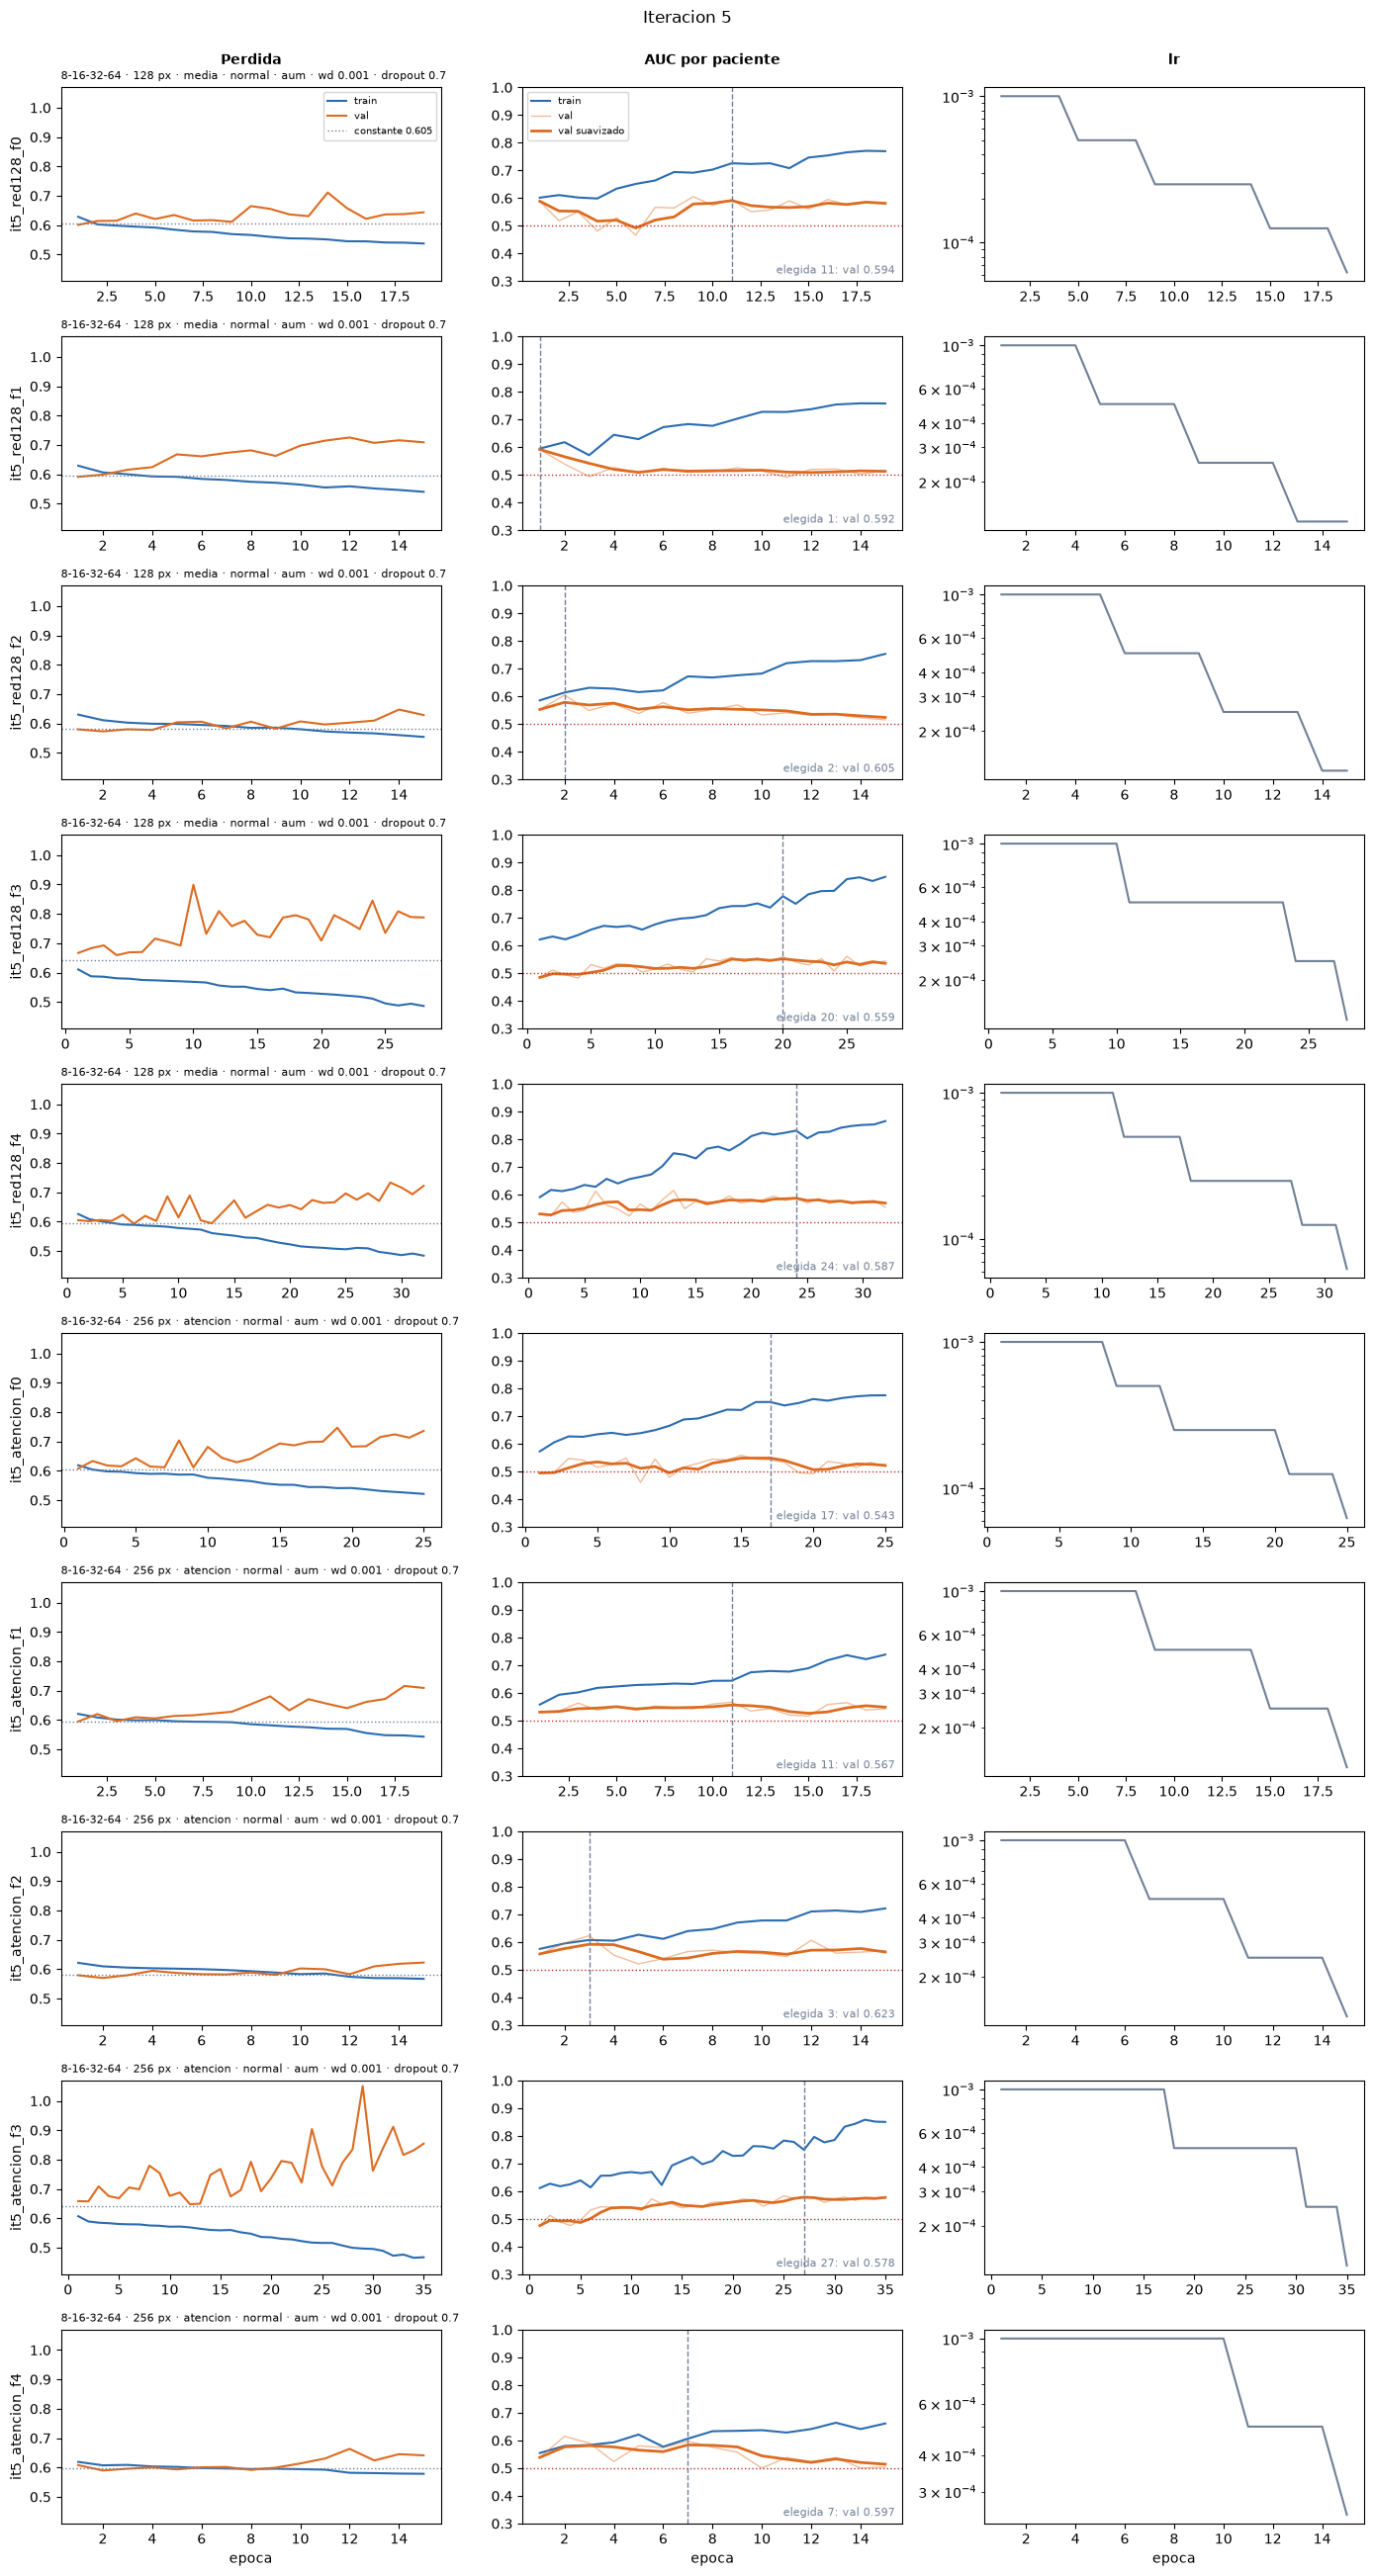

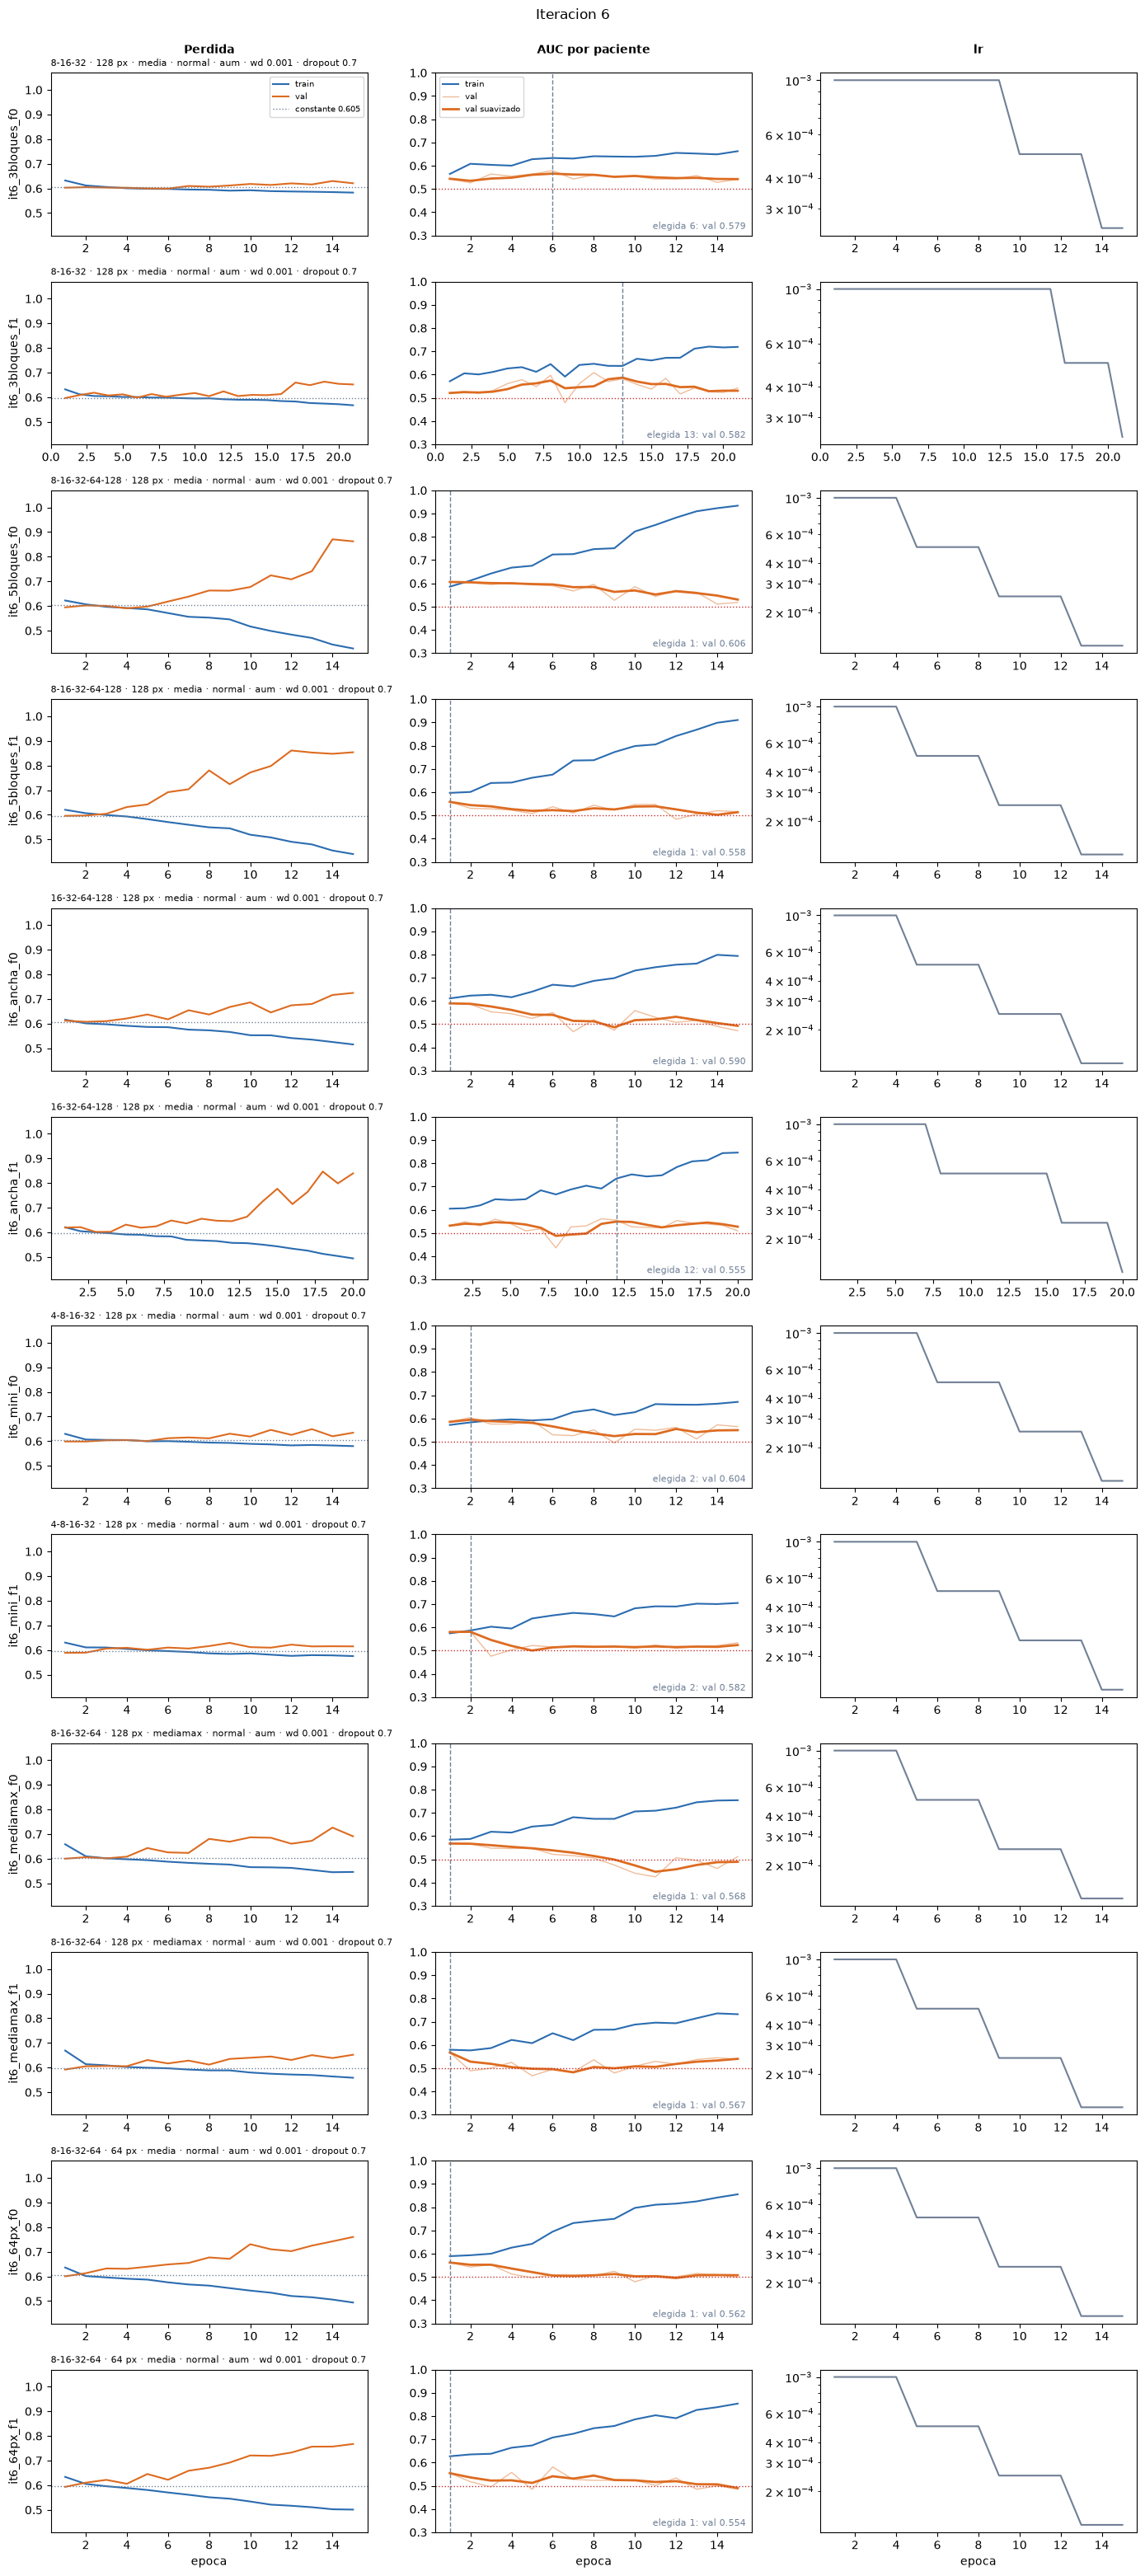

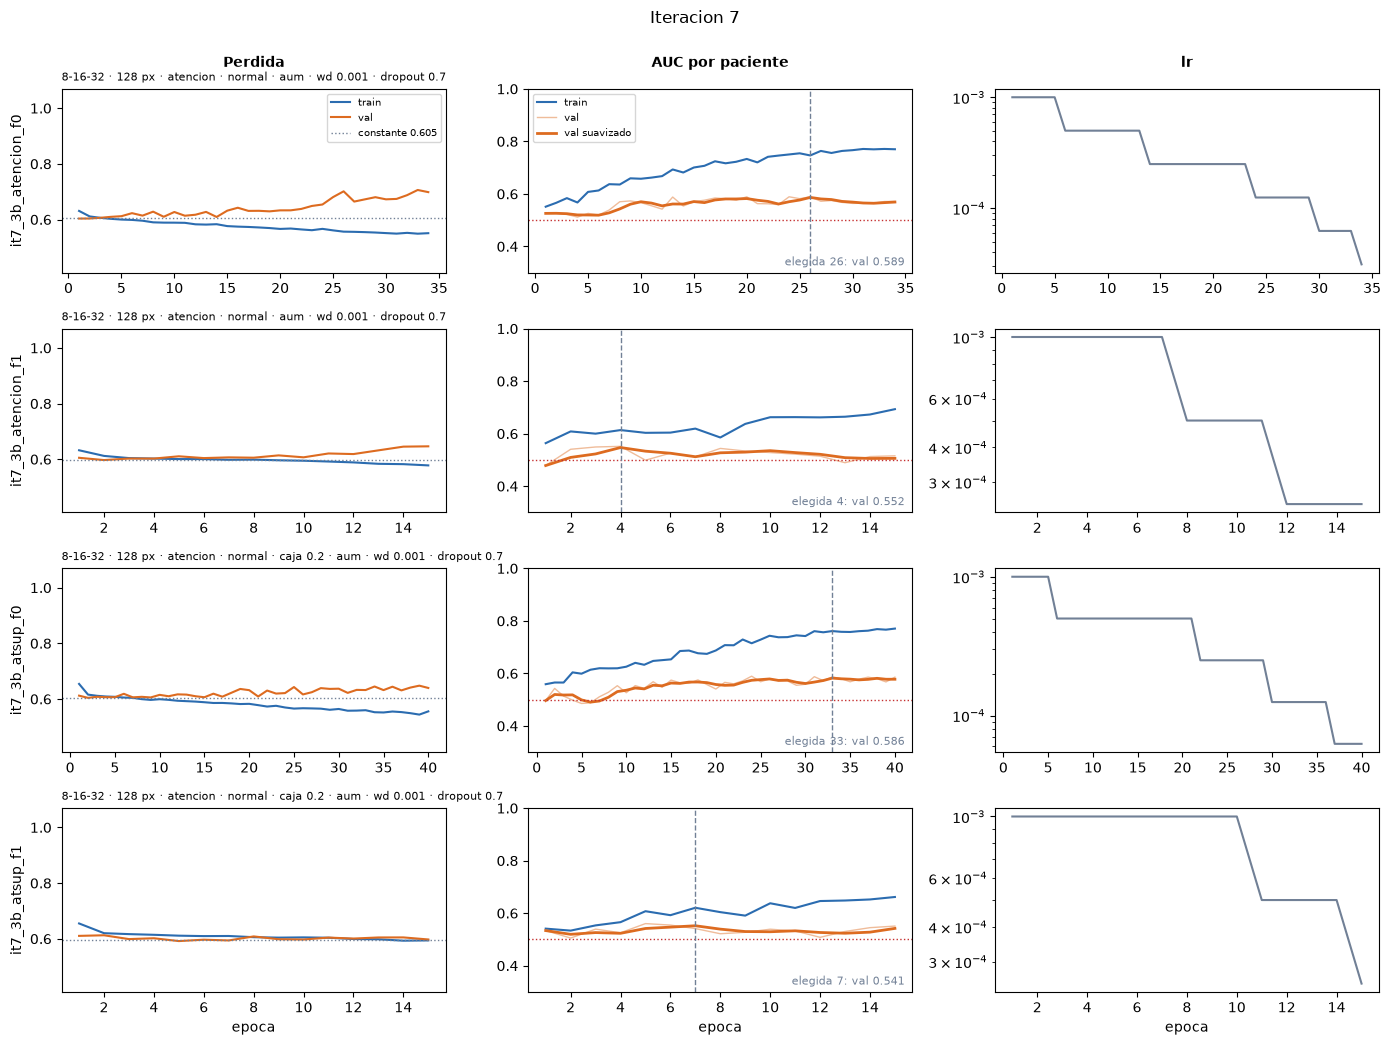

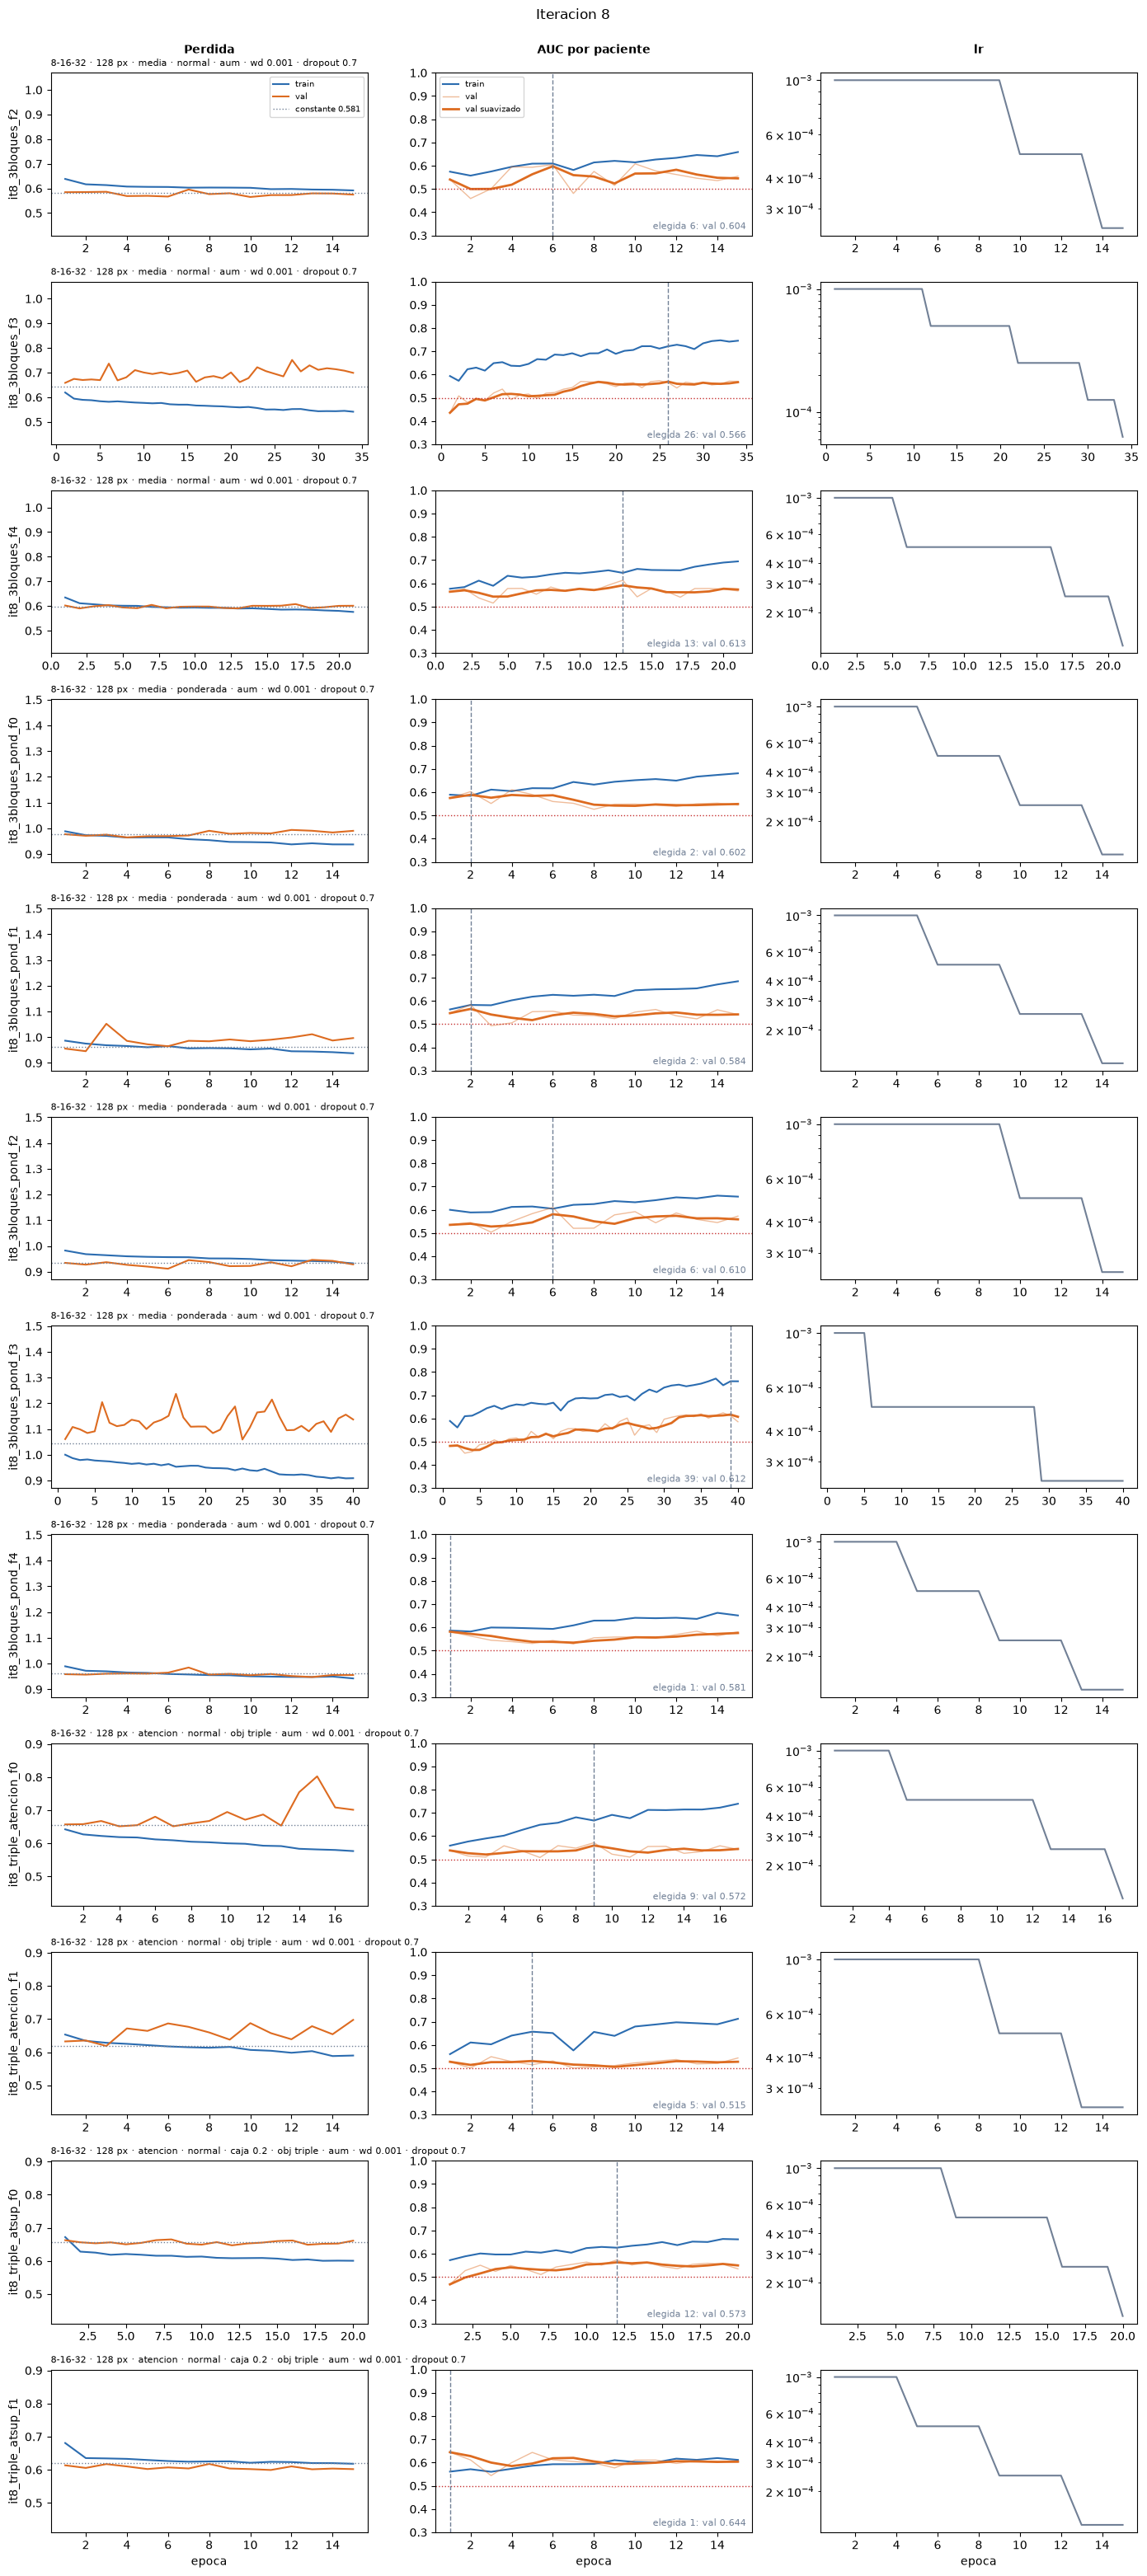

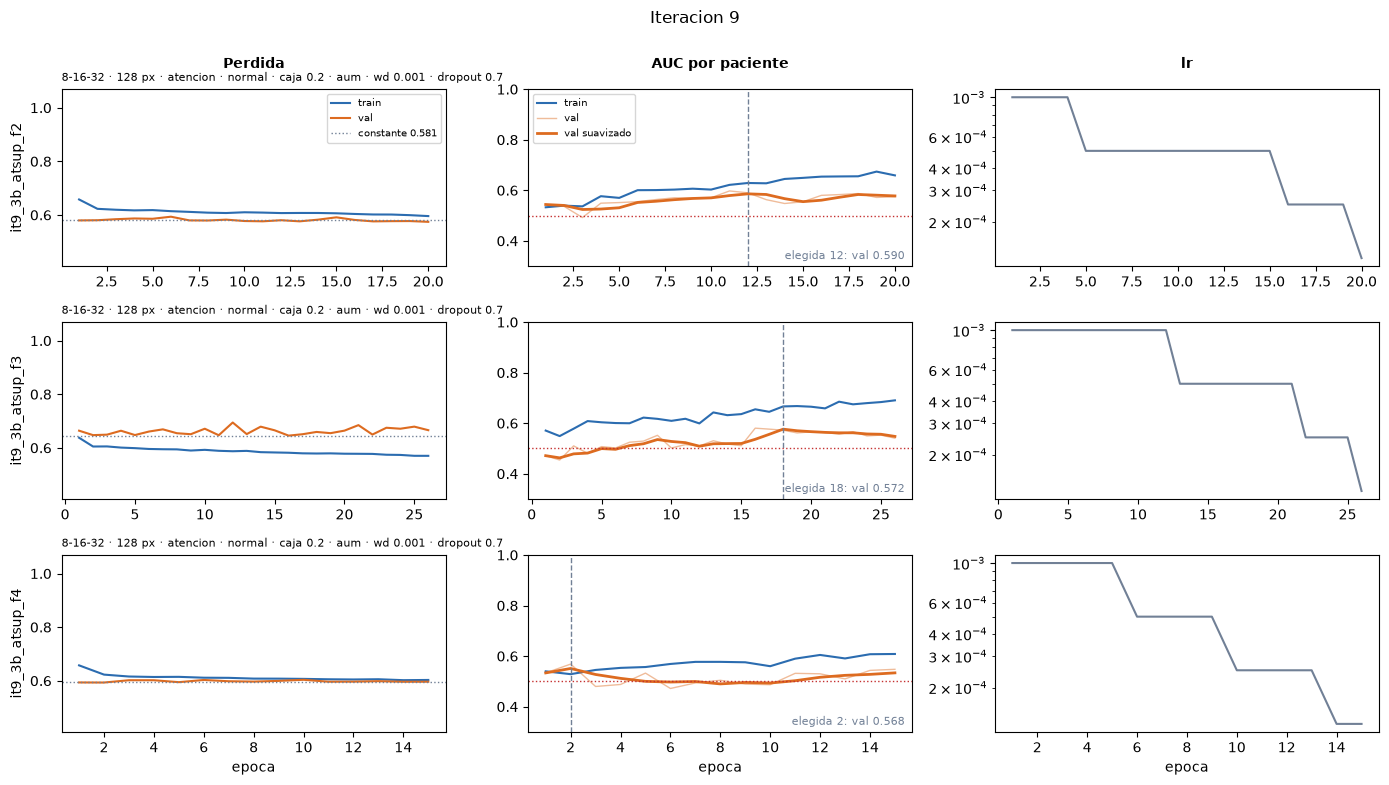

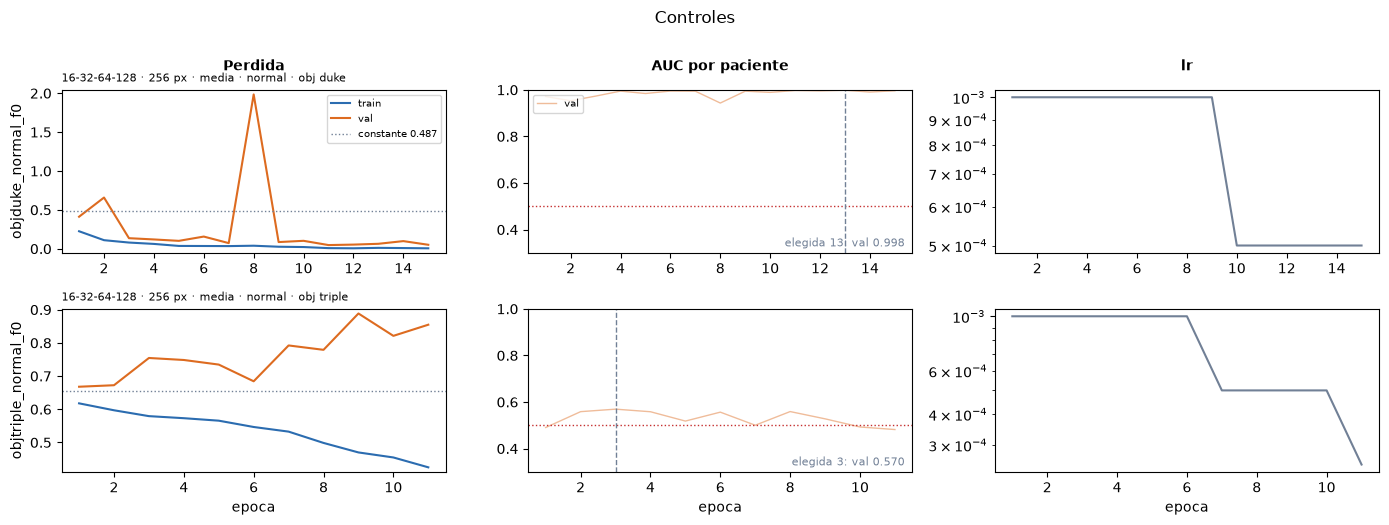

In [3]:
limites = fg.limites_perdida(list(ej.values()))
for iteracion, nombres in fg.EJECUCIONES.items():
    grupo = [ej[n] for n in nombres if n in ej]
    titulo = "Controles" if iteracion == "control" else f"Iteracion {iteracion}"
    fg.curvas_iteracion(grupo, limites, titulo)
    plt.show()

## C. Curvas superpuestas por configuracion de 5 folds

Los 5 folds de cada configuracion juntos: AUC de train (discontinua) y de validacion
(continua) a la izquierda, perdida a la derecha; el punto es la epoca elegida de cada fold.
Mirar cuanto se parecen los folds entre si (la variacion entre folds es la incertidumbre del
resultado) y en que epoca se separan train y validacion. Se guarda la del modelo congelado.

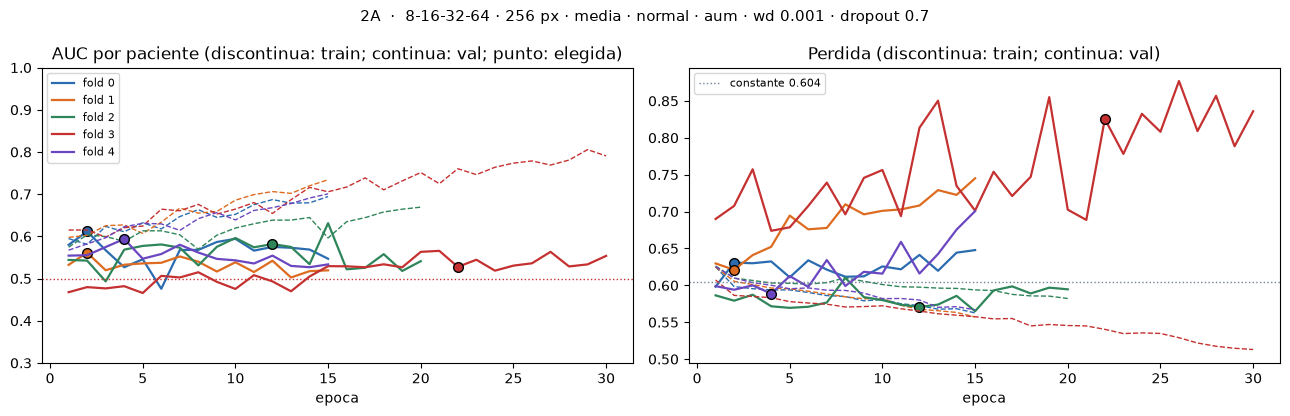

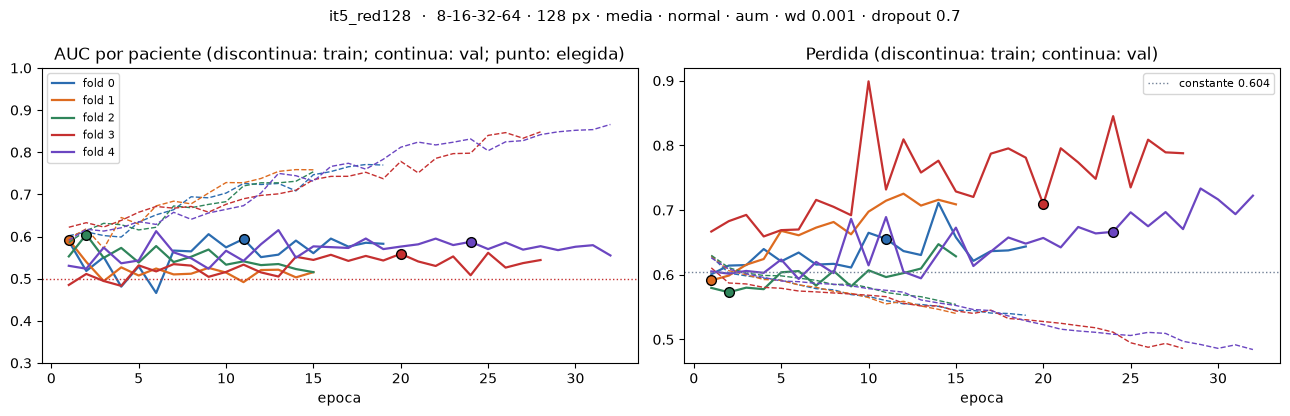

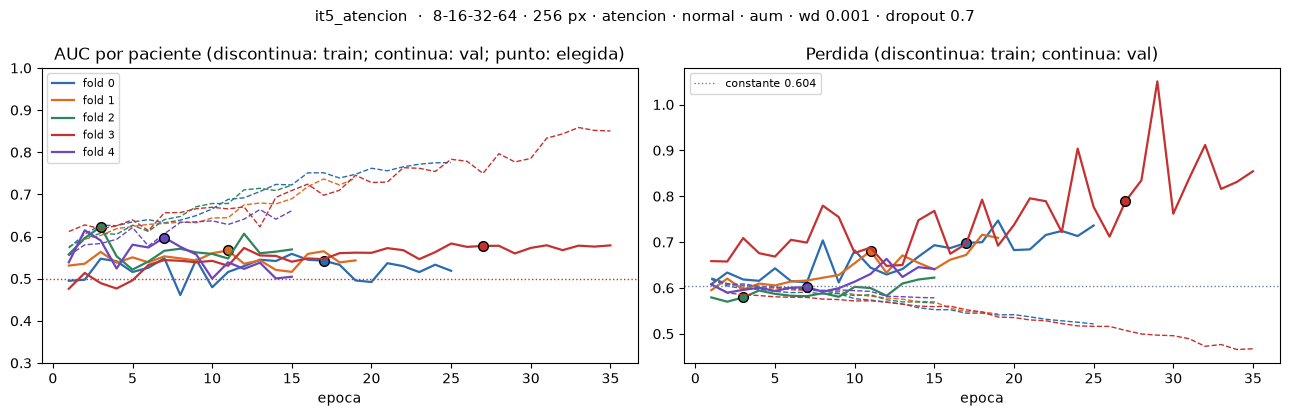

Guardada: docs\figuras\comparativa_congelado_5folds.png


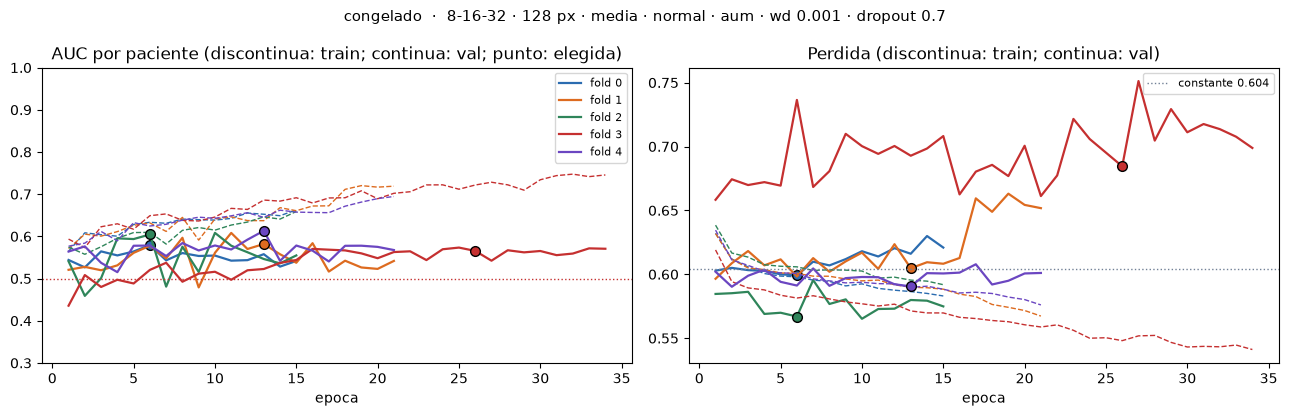

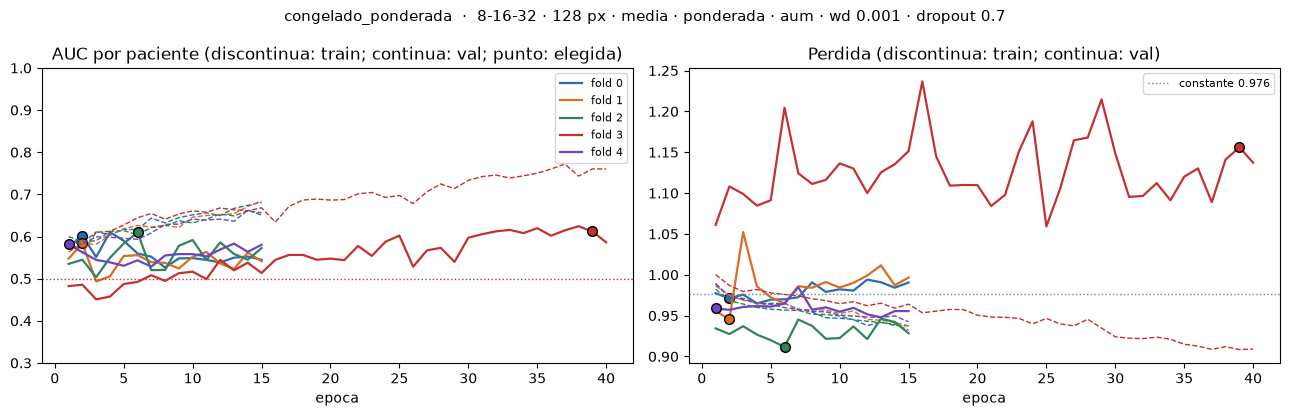

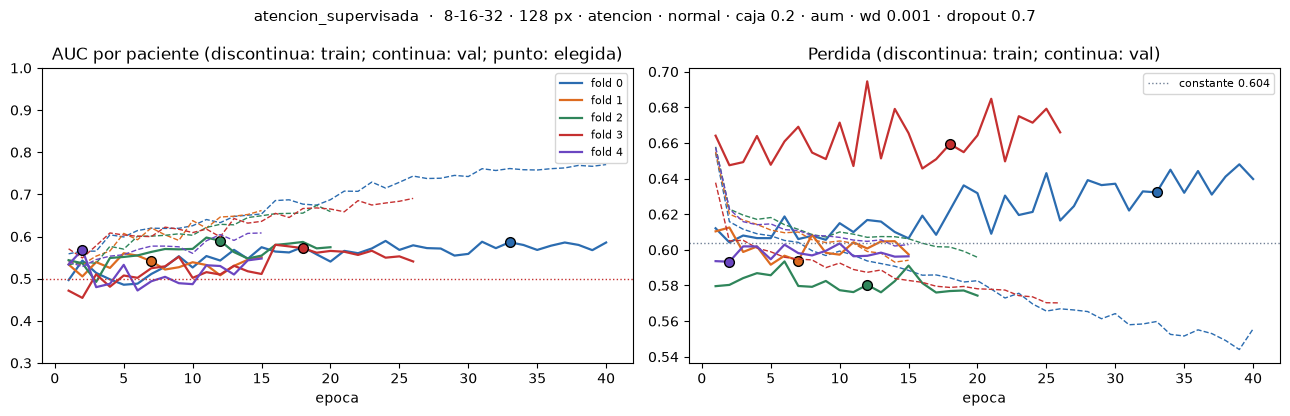

In [4]:
for nombre, nombres in fg.CINCO_FOLDS.items():
    if any(n not in ej for n in nombres):
        print(f"{nombre}: faltan folds, se salta")
        continue
    figura = fg.curvas_superpuestas([ej[n] for n in nombres], nombre)
    if nombre == fg.CONGELADO:
        print("Guardada:", fg.guardar(figura, "comparativa_congelado_5folds").relative_to(config.REPO))
    plt.show()

## D. Resumen de configuraciones

AUC de validacion medio de todas las epocas, media ± desviacion entre folds (las marcas
verticales son los folds): a la izquierda las configuraciones con 5 folds; a la derecha todas
las de pCR comparadas en los mismos folds 0 y 1. Lineas de referencia: azar (0,5) y «solo
cohorte» (predecir la tasa de pCR del hospital, de `results/analisis_*`). En rojo, el modelo
congelado. Mirar si las diferencias entre configuraciones superan la desviacion entre folds.

Solo cohorte: {'cinco': 0.549011615081858, 'f01': 0.5302592716252312}
Guardada: docs\figuras\comparativa_configuraciones.png


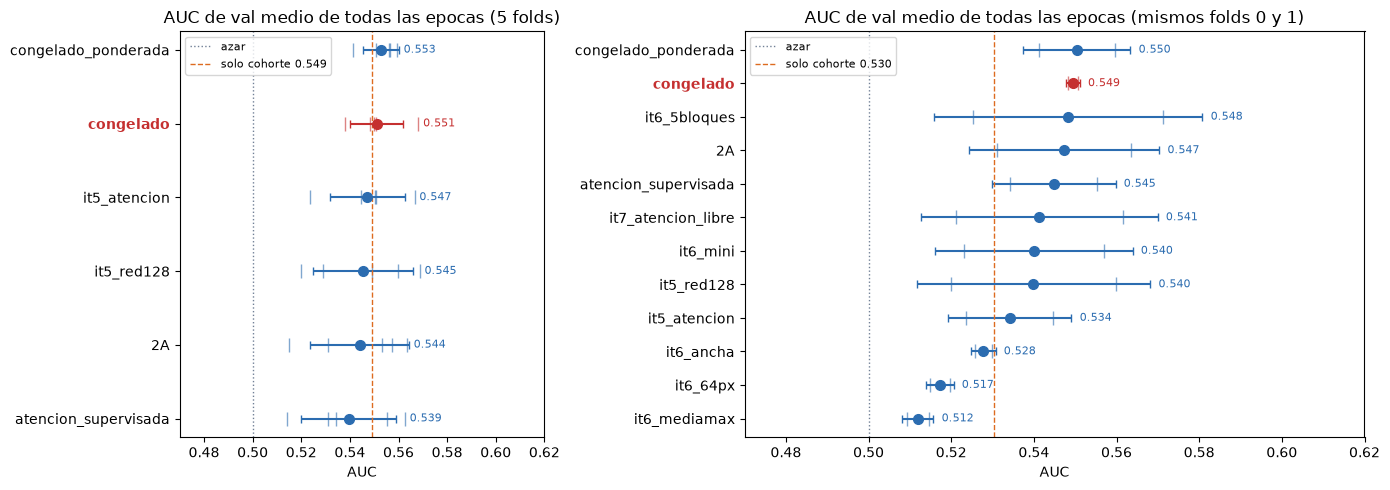

In [5]:
referencia = fg.solo_cohorte()
print("Solo cohorte:", referencia)
figura = fg.resumen_configuraciones(inv, referencia)
print("Guardada:", fg.guardar(figura, "comparativa_configuraciones").relative_to(config.REPO))
plt.show()

## E. Capacidad frente a memorizacion

Parametros (escala log) frente al AUC de train en la epoca 15 (cuanto memoriza) y frente al
AUC de validacion medio, para las variantes de la iteracion 6, la base de 128 px y el
congelado (media de los folds 0 y 1; la estrella es el congelado con sus 5 folds). Los
cuadrados son las redes cuyo mapa final ve la imagen entera (5 bloques y 64 px). Mirar si el
AUC de train y el de validacion se mueven juntos al cambiar el tamaño.

Guardada: docs\figuras\comparativa_capacidad_memorizacion.png


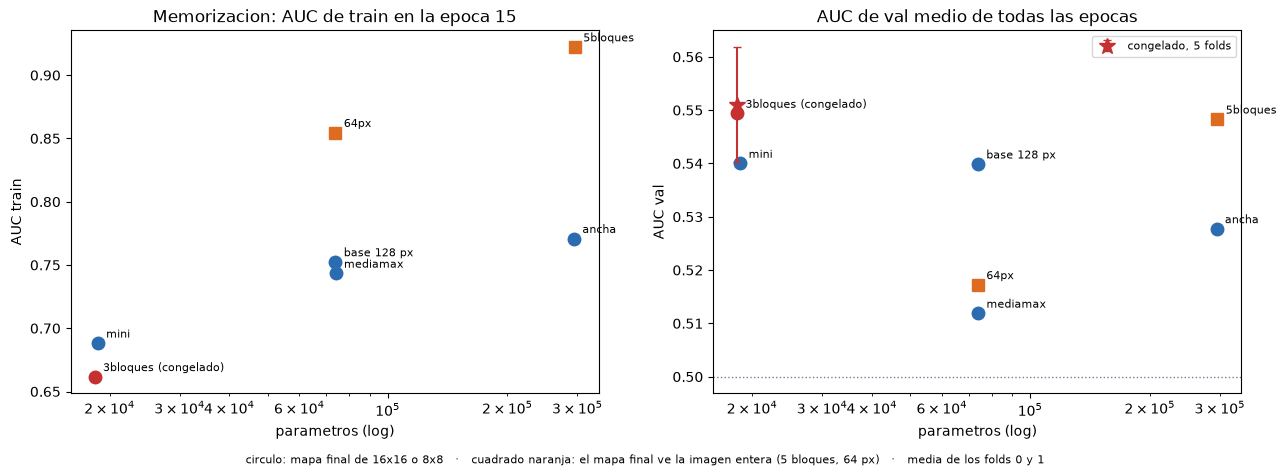

In [6]:
figura = fg.capacidad_memorizacion(inv)
print("Guardada:", fg.guardar(figura, "comparativa_capacidad_memorizacion").relative_to(config.REPO))
plt.show()

## F. Perdida normal frente a ponderada

Modelo congelado en los 5 folds, con las predicciones fuera de fold por paciente (media de
sus cortes, epoca elegida): histograma de la probabilidad para cada clase con cada perdida,
con lineas en 0,5 y en la tasa de pCR; a la derecha, sensibilidad y especificidad a 0,5 por
fold. Mirar donde caen las probabilidades respecto a 0,5 con cada perdida y si las dos clases
se separan mas con una que con otra.

Guardada: docs\figuras\comparativa_normal_vs_ponderada.png


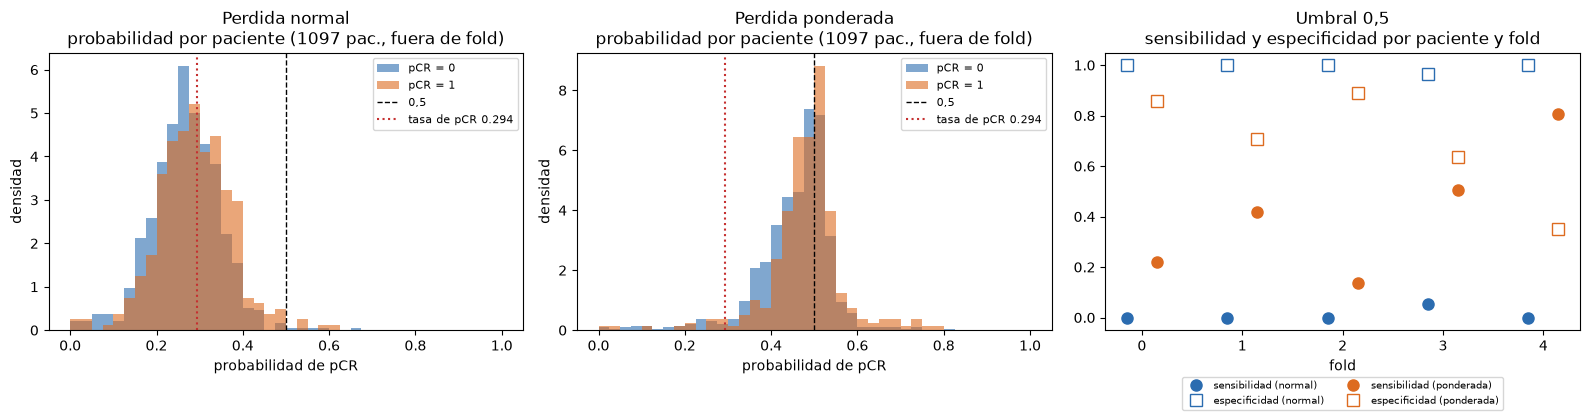

normal


,fold,sensibilidad_05,especificidad_05,prob_media_pcr0,prob_media_pcr1
0,0,0.000,1.000,0.275,0.289
1,1,0.000,1.000,0.232,0.249
2,2,0.000,1.000,0.242,0.264
3,3,0.053,0.966,0.277,0.306
4,4,0.000,1.000,0.312,0.334


ponderada


,fold,sensibilidad_05,especificidad_05,prob_media_pcr0,prob_media_pcr1
0,0,0.219,0.858,0.445,0.461
1,1,0.419,0.707,0.473,0.489
2,2,0.136,0.888,0.423,0.450
3,3,0.507,0.634,0.427,0.489
4,4,0.806,0.350,0.508,0.513


In [7]:
normal = [ej[n] for n in fg.CINCO_FOLDS["congelado"]]
ponderada = [ej[n] for n in fg.CINCO_FOLDS["congelado_ponderada"]]
figura = fg.normal_vs_ponderada(normal, ponderada)
print("Guardada:", fg.guardar(figura, "comparativa_normal_vs_ponderada").relative_to(config.REPO))
plt.show()
for nombre, grupo in (("normal", normal), ("ponderada", ponderada)):
    filas = []
    for e in grupo:
        p = fg.por_paciente(e["predicciones"])
        s, es = fg.sens_esp(p.prob, p.pcr)
        filas.append({"fold": e["config"]["fold"], "sensibilidad_05": s, "especificidad_05": es,
                      "prob_media_pcr0": p.prob[p.pcr == 0].mean(), "prob_media_pcr1": p.prob[p.pcr == 1].mean()})
    print(nombre)
    display(pd.DataFrame(filas).round(3))

## G. Cohortes y atajo del hospital

Izquierda: AUC fuera de fold por cohorte con IC 95 % por bootstrap de pacientes
(`src.utils.analisis_cv`, epoca elegida, asi que inflado) para el congelado con perdida
normal y ponderada y la atencion supervisada. Derecha: para las ejecuciones que lo registran
por epoca, el AUC de validacion entre pares del mismo hospital frente al AUC global; un modelo
que solo usara la cohorte quedaria en 0,5 en el eje vertical. Mirar la anchura de los IC
(spy1 y Duke tienen pocas pacientes) y si los puntos caen cerca de la diagonal o de 0,5.

Guardada: docs\figuras\comparativa_cohortes_hospital.png


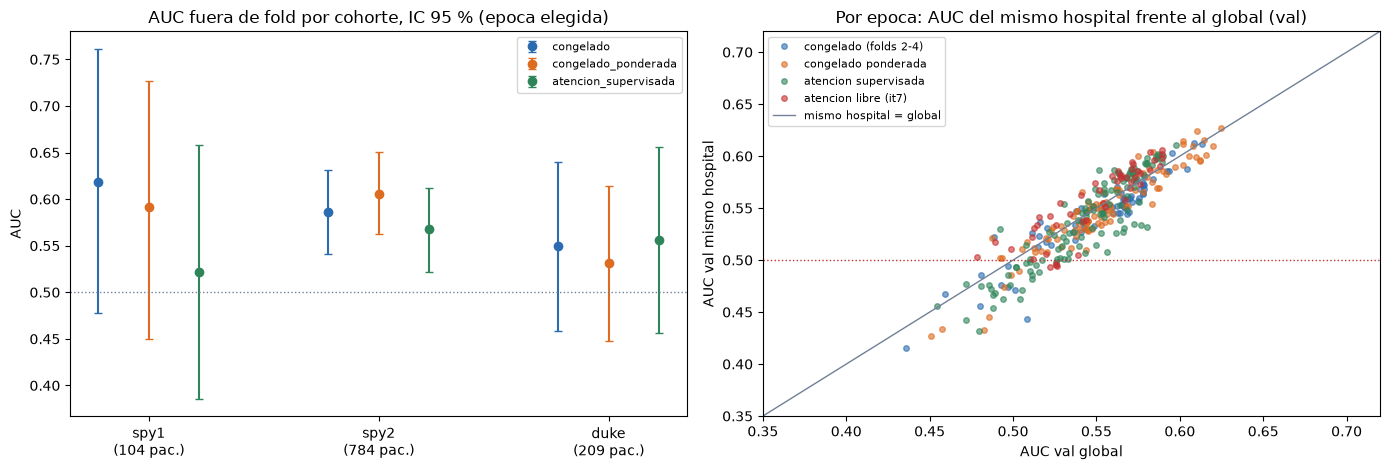

,congelado,congelado_ponderada,atencion_supervisada
spy1,0.618 [0.478-0.761] (104 pac.),0.592 [0.450-0.726] (104 pac.),0.522 [0.386-0.658] (104 pac.)
spy2,0.586 [0.541-0.631] (784 pac.),0.606 [0.562-0.650] (784 pac.),0.568 [0.521-0.612] (784 pac.)
duke,0.550 [0.458-0.639] (209 pac.),0.531 [0.448-0.615] (209 pac.),0.556 [0.456-0.656] (209 pac.)


In [8]:
from src.utils.analisis_cv import analizar

candidatos = ("congelado", "congelado_ponderada", "atencion_supervisada")
resumenes = {k: analizar(fg.CINCO_FOLDS[k], 2000, config.DEFECTO["semilla"])
             for k in candidatos if all(n in ej for n in fg.CINCO_FOLDS[k])}
por_epoca = {"congelado (folds 2-4)": normal, "congelado ponderada": ponderada,
             "atencion supervisada": [ej[n] for n in fg.CINCO_FOLDS["atencion_supervisada"] if n in ej],
             "atencion libre (it7)": [ej[n] for n in fg.FOLDS_0_1["it7_atencion_libre"]]}
figura = fg.cohortes_y_hospital(resumenes, por_epoca)
print("Guardada:", fg.guardar(figura, "comparativa_cohortes_hospital").relative_to(config.REPO))
plt.show()
display(pd.DataFrame({k: {c: f"{m['auc']:.3f} [{m['ic95'][0]:.3f}-{m['ic95'][1]:.3f}] ({m['pacientes']} pac.)"
                          for c, m in r["global"]["por_cohorte"].items()} for k, r in resumenes.items()}))

## H. Atencion

Arriba: masa de atencion que cae dentro de la caja del tumor (continua) frente a la fraccion
del mapa final que ocupa la caja (discontinua), en validacion y por epoca. Si la continua no
se separa de la discontinua, la atencion no prefiere el tumor. Abajo: 6 pacientes de
validacion del fold 0 con caja (3 pCR y 3 no pCR, elegidas al azar con semilla fija, corte
central): EARLY−PRE con la caja en verde y el mapa de atencion de la red libre y de la
supervisada encima.

Guardada: docs\figuras\comparativa_atencion_por_epoca.png


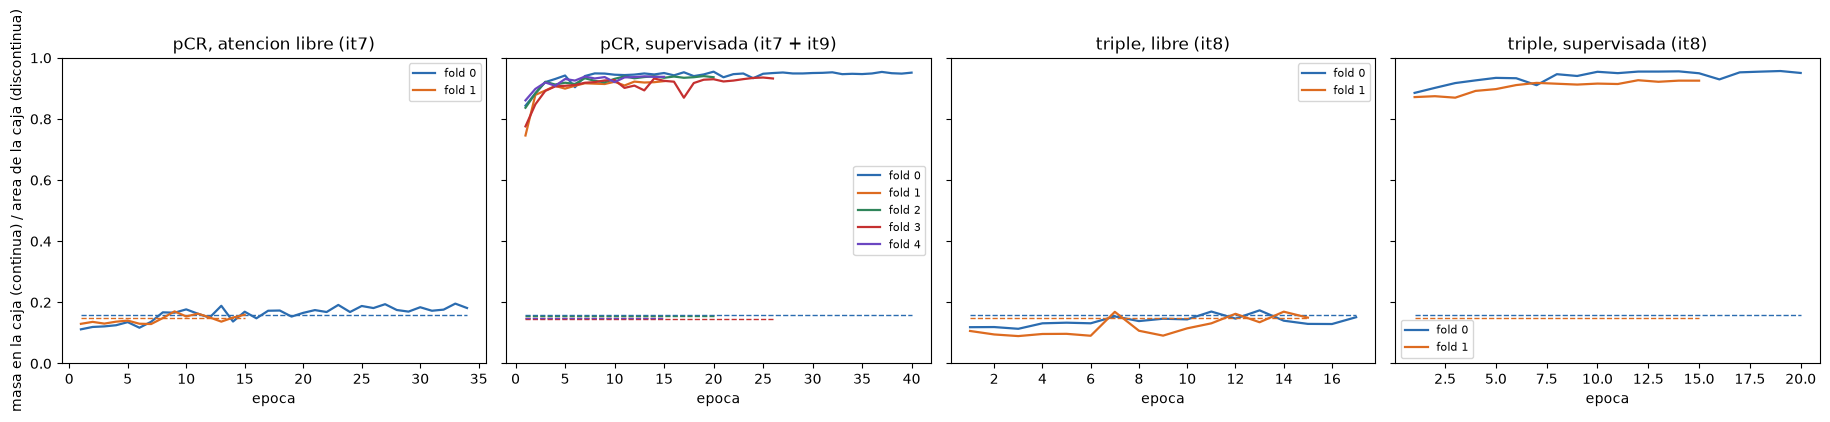

In [9]:
grupos = {"pCR, atencion libre (it7)": fg.FOLDS_0_1["it7_atencion_libre"],
          "pCR, supervisada (it7 + it9)": fg.CINCO_FOLDS["atencion_supervisada"],
          "triple, libre (it8)": ["it8_triple_atencion_f0", "it8_triple_atencion_f1"],
          "triple, supervisada (it8)": ["it8_triple_atsup_f0", "it8_triple_atsup_f1"]}
figura = fg.atencion_por_epoca({k: [ej[n] for n in v if n in ej] for k, v in grupos.items()})
print("Guardada:", fg.guardar(figura, "comparativa_atencion_por_epoca").relative_to(config.REPO))
plt.show()

Guardada: docs\figuras\comparativa_mapas_atencion.png


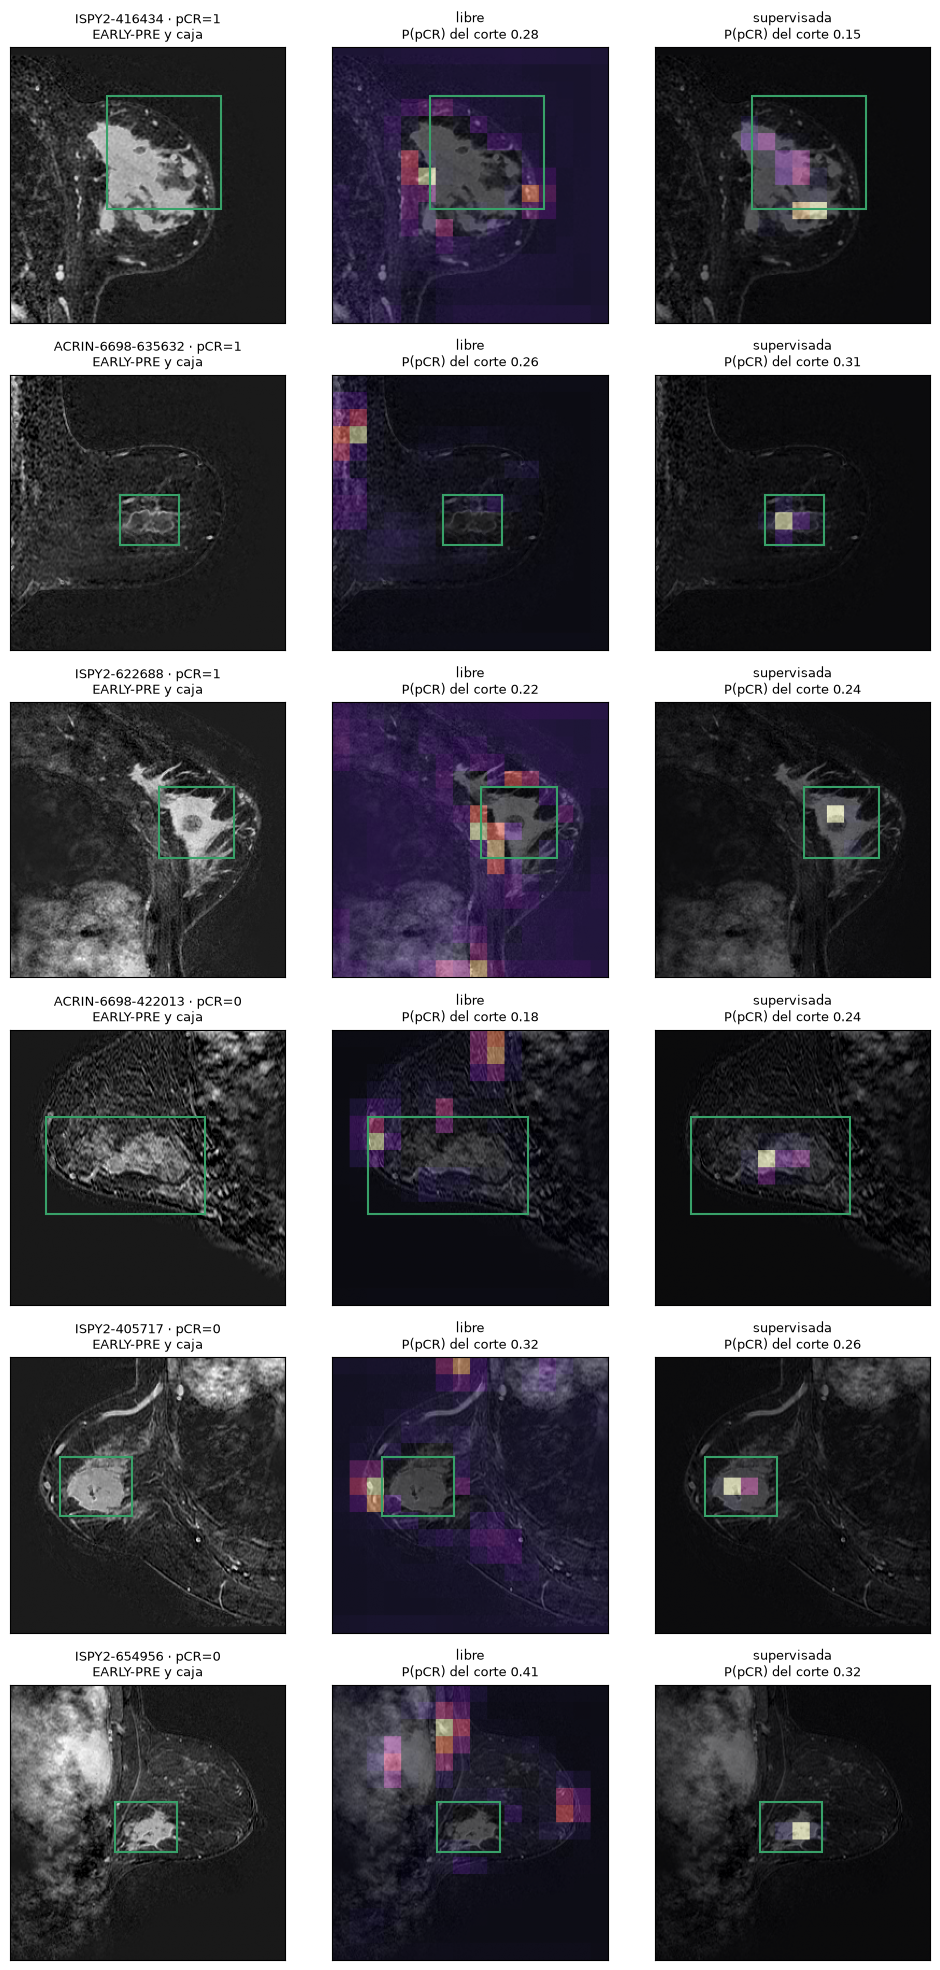

In [10]:
from src.data.tumor import caja_en_imagen
from src.models.cnn import cargar

pesos = {"libre": config.MODELOS / "it7_3b_atencion_f0.pt", "supervisada": config.MODELOS / "it7_3b_atsup_f0.pt"}
if not all(p.exists() for p in pesos.values()):
    print("Faltan los pesos", [p.name for p in pesos.values() if not p.exists()], "-> se salta")
else:
    uc = config.utils()
    _, valida = uc.particion(uc.cargar_samples(), fold_val=0)          # solo validacion del fold 0
    pacientes = uc.cargar_patients().set_index("pid")
    cajas = {p: caja_en_imagen(pacientes.loc[p]) for p in valida.patient_id.unique()}
    elegidos = fg.elegir_pacientes(valida, cajas)
    imagenes = np.stack([uc.cargar_imagen(f) for f in elegidos.itertuples()])
    redes = {nombre: cargar(ruta)[0] for nombre, ruta in pesos.items()}
    figura = fg.mapas_atencion(redes, elegidos, imagenes, [cajas[p] for p in elegidos.patient_id])
    print("Guardada:", fg.guardar(figura, "comparativa_mapas_atencion").relative_to(config.REPO))
    plt.show()

## I. Controles

La misma red base (4 bloques, 256 px) con dos etiquetas de diagnostico en lugar de pCR:
la cohorte Duke (control positivo: se ve en la imagen, porque cada hospital procesa
distinto) y el subtipo triple negativo (control negativo). Mirar si la perdida de validacion
baja de la constante y si el AUC de validacion se separa de 0,5. Estas ejecuciones son
anteriores a la iteracion 1 y no registran el AUC de train.

Guardada: docs\figuras\comparativa_controles.png


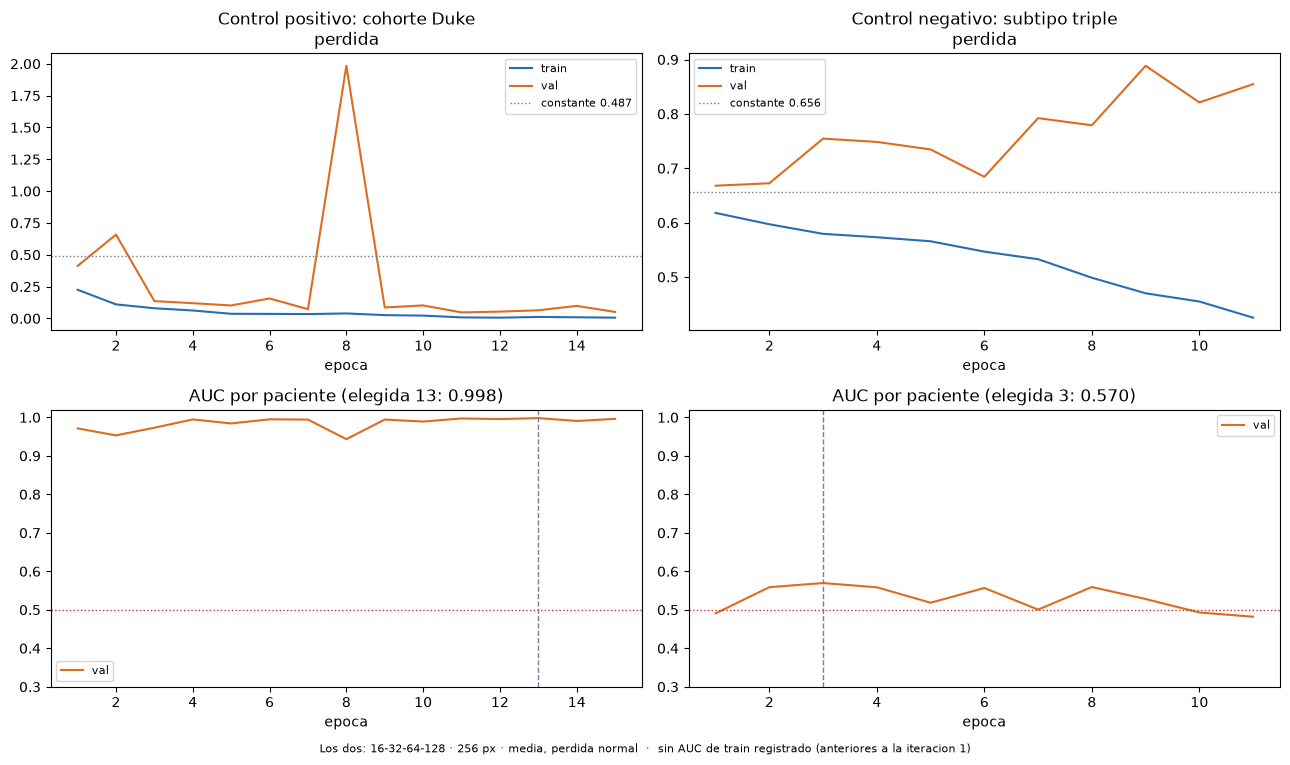

In [11]:
figura = fg.controles(ej["objduke_normal_f0"], ej["objtriple_normal_f0"])
print("Guardada:", fg.guardar(figura, "comparativa_controles").relative_to(config.REPO))
plt.show()

## J. Corte suelto frente a paciente

El modelo se evalua por paciente (media de ~10 cortes), pero la app recibe un solo corte.
Con el congelado (perdida normal, fuera de fold, 5 folds): distribucion de la probabilidad por
corte frente a la media por paciente, y desviacion de las probabilidades entre los cortes de
cada paciente. Mirar cuanto mas ancha es la distribucion por corte y el tamaño de la
desviacion dentro de una paciente comparado con la separacion entre clases de la seccion F.

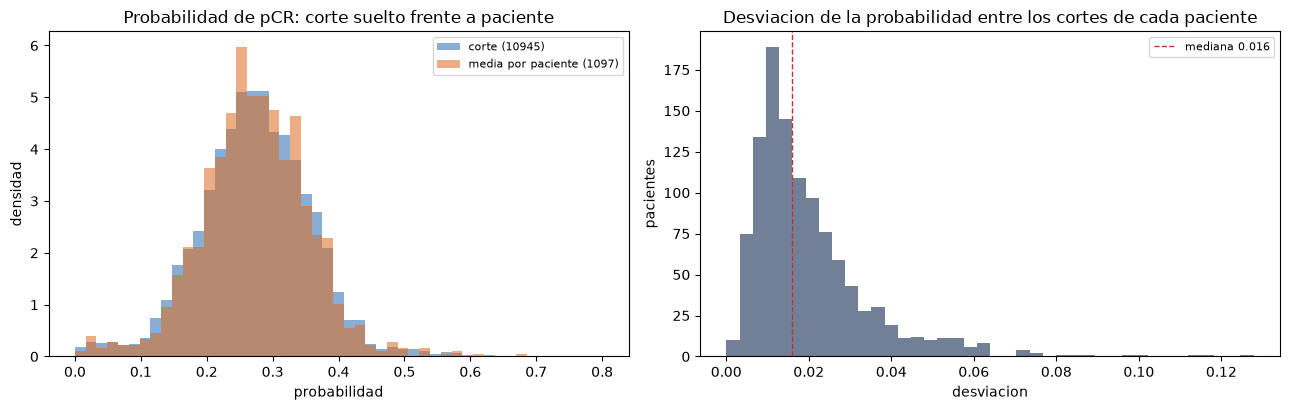

cortes: 10945, pacientes: 1097, cortes por paciente: mediana 10
desviacion entre cortes de una paciente: mediana 0.016, percentil 90 0.037
desviacion de la media por paciente entre pacientes: 0.082; de la probabilidad por corte: 0.085


In [12]:
fg.corte_vs_paciente(normal)
plt.show()
cortes = pd.concat([e["predicciones"] for e in normal])
pac = pd.concat([fg.por_paciente(e["predicciones"]) for e in normal])
print(f"cortes: {len(cortes)}, pacientes: {len(pac)}, cortes por paciente: mediana {pac.cortes.median():.0f}")
print(f"desviacion entre cortes de una paciente: mediana {pac.desviacion.median():.3f}, "
      f"percentil 90 {pac.desviacion.quantile(0.9):.3f}")
print(f"desviacion de la media por paciente entre pacientes: {pac.prob.std():.3f}; "
      f"de la probabilidad por corte: {cortes.prob.std():.3f}")

## K. Umbral y calibracion

El umbral (especificidad ≥ 0,90 por paciente) y la calibracion los calcula otro script; aqui
solo se muestran sus figuras si ya existen (en `results/umbral/` o `docs/figuras/`), sin
recalcular nada.

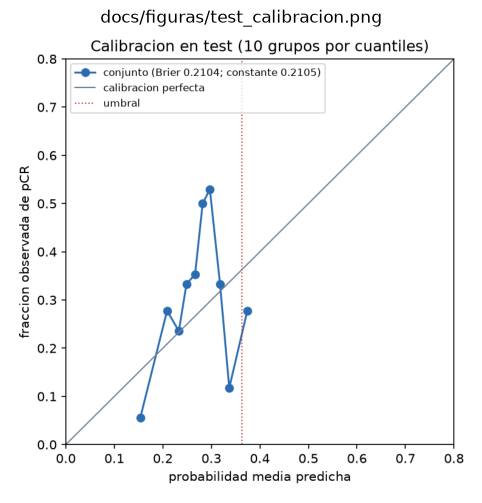

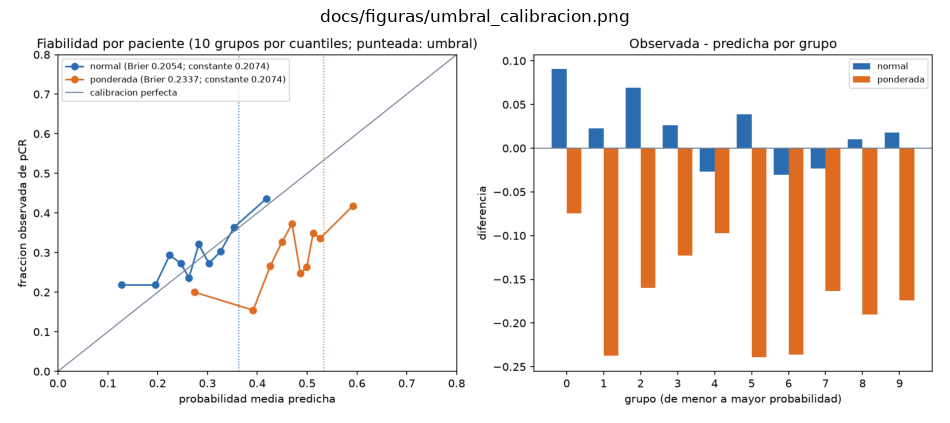

In [13]:
candidatas = sorted((config.RESULTADOS / "umbral").glob("*.png")) if (config.RESULTADOS / "umbral").exists() else []
candidatas += [p for p in sorted(config.FIGURAS.glob("*.png"))
               if any(clave in p.stem for clave in ("umbral", "calibracion"))]
if not candidatas:
    print("Aun no hay figuras del umbral ni de calibracion: se salta.")
for ruta in candidatas:
    plt.figure(figsize=(12, 6))
    plt.imshow(plt.imread(ruta))
    plt.axis("off")
    plt.title(ruta.relative_to(config.REPO).as_posix())
    plt.show()